<a href="https://colab.research.google.com/github/VizDataWorks/eCommerce_data_analysis/blob/main/ecommerce-challenge/notebooks/04_black_friday_impact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Black Friday's impact on annual sales, by customer segment

**Question:** What is the impact of Black Friday on annual sales (volume and revenue) by customer segment?

**Short answer:** **Black Friday is the busiest day of the year but a small part of annual sales:** about 4× a normal day's orders, yet only about 1% of the year's orders and revenue. Revenue fell 24% in 2025. Young Parents and Fashion Shoppers responded most in 2024; Fitness Buffs were the only segment to grow in 2025.

**Business rules (from the brief)**
- **Black Friday:** 20% off every order, by the customer's local date (Nov 29, 2024; Nov 28, 2025).
- Referral discount, shipping and carrier fee as in notebook 03.

**Approach**
- Delivered orders only. **Volume** = orders and units; **revenue** = item sales after discounts, excluding shipping.
- "× an average day" compares Black Friday with the other days of the same year.
- Orders from buyers not in the customer table are shown as *Unknown*.

## 1. Setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Get the project data from GitHub: no Google Drive or sign-in needed
REPO = "https://github.com/VizDataWorks/CapitalOne_DataAnalysis.git"
!rm -rf repo
!git clone -q --depth 1 {REPO} repo
CLEAN = os.path.join("repo", "ecommerce-challenge", "data", "clean")

# Business rules from the brief
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])
REFERRAL_DISCOUNT = 0.10

## 2. Load data

In [2]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"),
                        usecols=["buyer_id", "is_referred", "customer_segment"], dtype={"is_referred": "Int64"})
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), usecols=["sku_id", "price"])
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv.gz"),
                    usecols=["order_id", "buyer_id", "sku_id", "quantity", "order_datetime", "is_revenue"],
                    parse_dates=["order_datetime"])   # order_datetime is the buyer's local time

## 3. Build one row per delivered order

Same rules as notebook 03: Black Friday discount first, then the referral discount, then shipping and profit.

In [3]:
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(products, on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price

orders = (lines.groupby("order_id")
               .agg(buyer_id=("buyer_id", "first"), order_time=("order_datetime", "min"),
                    units=("quantity", "sum"), list_revenue=("list_revenue", "sum"))
               .reset_index()
               .merge(customers, on="buyer_id", how="left"))

# Black Friday first: 20% off, by the buyer's local date
orders["is_black_friday"] = orders.order_time.dt.normalize().isin(BLACK_FRIDAYS)
orders["black_friday_discount"] = orders.list_revenue.where(orders.is_black_friday, 0) * BLACK_FRIDAY_DISCOUNT
pre_referral = orders.list_revenue - orders.black_friday_discount

# Then 10% off a referred buyer's first delivered order
first_orders = (orders.dropna(subset=["buyer_id", "order_time"])
                      .sort_values(["order_time", "order_id"])
                      .drop_duplicates("buyer_id").order_id)
is_referral_order = orders.order_id.isin(first_orders) & orders.is_referred.eq(1).fillna(False)
orders["revenue"] = pre_referral - pre_referral.where(is_referral_order, 0) * REFERRAL_DISCOUNT

orders = orders.dropna(subset=["order_time"])
orders["date"] = orders.order_time.dt.normalize()
orders["year"] = orders.date.dt.year
orders["customer_segment"] = orders.customer_segment.fillna("Unknown")

print(f"{len(orders):,} delivered orders, {orders.is_black_friday.sum():,} of them on Black Friday")

234,968 delivered orders, 2,574 of them on Black Friday


## 4. Overall impact, by year

In [4]:
def bf_summary(d):
    """Black Friday vs the other days of the same year, for one group of orders."""
    bf, other = d[d.is_black_friday], d[~d.is_black_friday]
    other_days = pd.Timestamp(d.date.dt.year.iloc[0], 12, 31).dayofyear - 1
    return pd.Series({
        "bf_orders": len(bf),
        "bf_order_share": len(bf) / len(d),
        "bf_units": bf.units.sum(),
        "bf_revenue": bf.revenue.sum(),
        "bf_revenue_share": bf.revenue.sum() / d.revenue.sum(),
        "orders_x_avg_day": len(bf) / (len(other) / other_days),
        "revenue_x_avg_day": bf.revenue.sum() / (other.revenue.sum() / other_days),
        "bf_order_value_before_discount": bf.list_revenue.mean(),
        "discount_cost": bf.black_friday_discount.sum(),
    })


# Display label and number format for each measure
ROWS = {
    "bf_orders": ("Black Friday orders", "{:,.0f}"),
    "bf_order_share": ("Share of year's orders", "{:.2%}"),
    "bf_units": ("Black Friday units", "{:,.0f}"),
    "bf_revenue": ("Black Friday revenue", "${:,.0f}"),
    "bf_revenue_share": ("Share of year's revenue", "{:.2%}"),
    "orders_x_avg_day": ("Orders vs avg day", "{:.1f}×"),
    "revenue_x_avg_day": ("Revenue vs avg day", "{:.1f}×"),
    "bf_order_value_before_discount": ("Order value before discount", "${:,.2f}"),
    "discount_cost": ("Cost of the 20% discount", "${:,.0f}"),
}

overall = orders.groupby("year").apply(bf_summary, include_groups=False).T
shown = overall.apply(lambda row: row.map(ROWS[row.name][1].format), axis=1)
shown["2025 vs 2024"] = (overall[2025] / overall[2024] - 1).map("{:+.1%}".format)
shown.rename(index=lambda k: ROWS[k][0])

year,2024,2025,2025 vs 2024
Black Friday orders,"1,316","1,258",-4.4%
Share of year's orders,1.12%,1.07%,-4.3%
Black Friday units,"2,918","2,772",-5.0%
Black Friday revenue,"$118,346","$89,535",-24.3%
Share of year's revenue,1.28%,0.96%,-24.5%
Orders vs avg day,4.1×,3.9×,-4.6%
Revenue vs avg day,4.7×,3.5×,-24.9%
Order value before discount,$112.41,$88.97,-20.9%
Cost of the 20% discount,"$29,587","$22,384",-24.3%


## 5. By customer segment

Revenue is after discounts. "× avg day" compares Black Friday with that segment's average day in the same year.

In [5]:
cols = ["bf_orders", "bf_order_share", "bf_revenue", "bf_revenue_share", "revenue_x_avg_day"]
by_segment = (orders.groupby(["customer_segment", "year"]).apply(bf_summary, include_groups=False)[cols]
                    .unstack("year")
                    .sort_values(("bf_revenue", 2024), ascending=False))

# Unknown (buyers not in the customer table) goes last
order = [s for s in by_segment.index if s != "Unknown"] + ["Unknown"]
by_segment = (by_segment.loc[order]
                        .rename(index={"Unknown": "Unknown (buyer not in customers)"})
                        .rename_axis("Segment"))

(by_segment.style
           .format({c: ROWS[c[0]][1] for c in by_segment.columns})
           .format_index(lambda k: ROWS[k][0], axis=1, level=0)
           .background_gradient(cmap="Blues", subset=[("revenue_x_avg_day", 2024), ("revenue_x_avg_day", 2025)]))

In [6]:
bf = by_segment[["bf_orders", "bf_revenue"]]
seg_yoy = (bf.xs(2025, axis=1, level="year") / bf.xs(2024, axis=1, level="year") - 1)
(seg_yoy.set_axis(["orders", "revenue"], axis=1)
        .sort_values("revenue", ascending=False)
        .rename_axis("Black Friday 2025 vs 2024")
        .style.format("{:+.1%}"))

,orders,revenue
Black Friday 2025 vs 2024,,
Fitness Buff,+15.6%,+6.6%
Cozy Homemaker,-2.4%,-4.3%
Bargain Hunter,-2.0%,-18.3%
Unknown (buyer not in customers),+19.0%,-18.9%
Home Organizer,+1.3%,-25.2%
Fashion Shopper,-7.0%,-27.7%
Tech Enthusiast,-19.1%,-30.6%
Beauty Lover,-17.0%,-33.8%
Young Parent,-13.1%,-36.0%


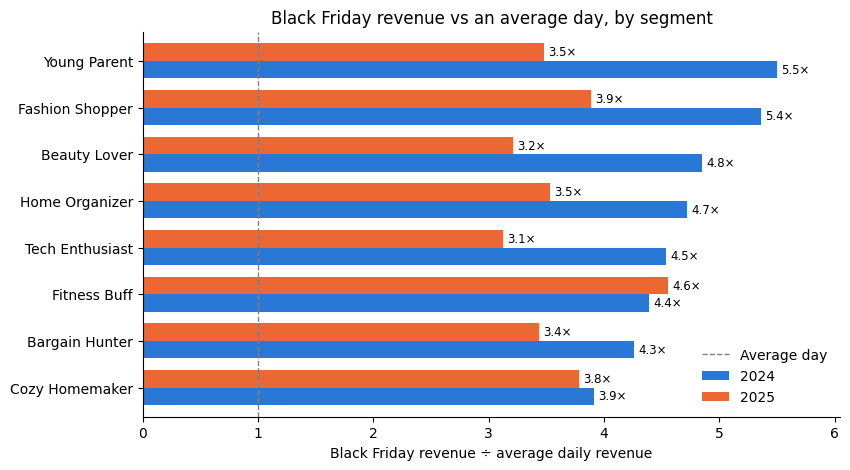

In [7]:
lift = by_segment["revenue_x_avg_day"].drop(index="Unknown (buyer not in customers)").sort_values(2024)

ax = lift.plot.barh(figsize=(9, 5), width=0.75, color=["#2a78d6", "#eb6834"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:.1f}×", padding=3, fontsize=8.5)
ax.axvline(1, color="grey", linestyle="--", linewidth=1, label="Average day")
ax.set(title="Black Friday revenue vs an average day, by segment",
       xlabel="Black Friday revenue ÷ average daily revenue", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.margins(x=0.1)
plt.show()

## 6. Conclusion

Black Friday is a big day but a small share of the year. It brings about 4× an average day's orders (1,316 in 2024, 1,258 in 2025) but only about 1.1% of annual orders and 1.0–1.3% of annual revenue.

2025 was weaker: orders fell 4% but revenue fell 24% ($118k to $90k), because the average order before discount dropped from $112 to $89. The 20% discount cost $30k and $22k.
By segment: Tech Enthusiasts bring the most Black Friday revenue ($32k in 2024). Young Parents and Fashion Shoppers responded most in 2024 (5.5× and 5.4× their average day), then fell back hardest in 2025 (revenue −36% and −28%). Fitness Buffs were the only segment to grow (+7% revenue).
Limits

Two Black Fridays only, so differences between segments may partly be noise.
"× an average day" includes weekends; against a typical Friday the lift would be a little lower.